# Getting Started

In [1]:
import os
from pathlib import Path
from zipfile import ZipFile

import pandas as pd
import requests
import torch
from tirex2 import TimeseriesType, load_model
from tirex2.plotting import plot_multivariate  # requires matplotlib to be installed


In [2]:
target_dir = Path("data/")

## Tirex-2
Short snippet to load the model in the data folder and generate a first output


The necessary package should be installed via `pip install tirex-2` or `uv add tirex-2`. <br>
To load the model it is recommend to set an HF_TOKEN via `export HF_TOKEN=<your-hf-token>` but not necessary.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

/root/projects/aiviz/.venv/lib/python3.14/site-packages/triton/language/core.py:2625: UserWarning: tl.make_block_ptr is deprecated. Use TensorDescriptor or tl.make_tensor_descriptor instead.
  warn("tl.make_block_ptr is deprecated. Use TensorDescriptor or tl.make_tensor_descriptor instead.")


ninja: no work to do.


/tmp/ipykernel_12481/1824440209.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


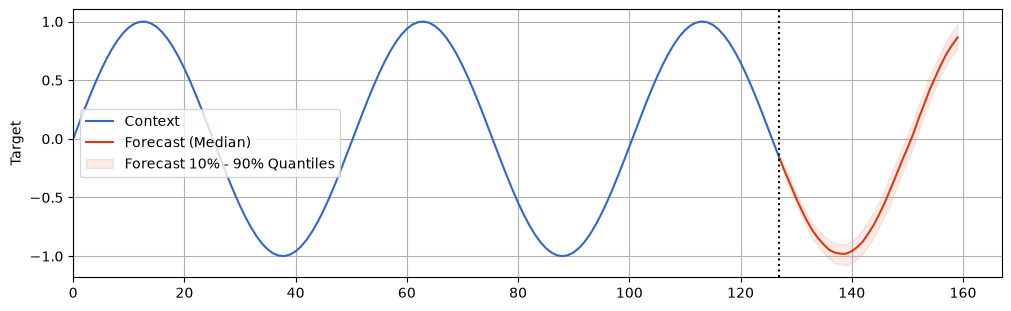

In [3]:
# use `device="cuda"` if cuda is available
device = "cuda" if torch.cuda.is_available() else "cpu"

## hf_args
hf_kwargs = {"cache_dir": target_dir / "tirex"}

# load model
model = load_model("NX-AI/TiRex-2", device=device, hf_kwargs=hf_kwargs)

# generate data - target expects time series of shape (n_targets, context_length)
context = torch.sin(torch.arange(128).float() / 8)
ts = TimeseriesType(
    target=context.unsqueeze(0), past_covariates=None, future_covariates=None
)

# perform forecast - each forecast is of shape (n_targets, 9 quantiles, prediction_length)
forecast = model.forecast([ts], prediction_length=32, output_type="numpy")[0]

# visualize result
fig = plot_multivariate(ts, forecast, engine="matplotlib")
fig.show()

## UCR Dataset

Snippet to download the data and unpack it to the data folder

In [14]:
# Define the URL and target directory
url = "https://www.cs.ucr.edu/~eamonn/time_series_data_2018/UCRArchive_2018.zip"
pw = "someone"

# Create the target directory if it doesn't exist
os.makedirs(target_dir, exist_ok=True)

# Download the file
print(f"Downloading UCRArchive_2018.zip from {url} to {target_dir}")
if os.path.exists(target_dir / "UCRArchive_2018.zip"):
    print(f"{target_dir / 'UCRArchive_2018.zip'} already exists. Skipping download.")
else:
    zip_path = os.path.join(target_dir, "UCRArchive_2018.zip")
    response = requests.get(url)
    with open(zip_path, "wb") as f:
        f.write(response.content)
    print(f"Downloaded {zip_path}")


# Unpack the zip file
print(f"Unpacking UCRArchive_2018.zip to {target_dir}")
if os.path.exists(zip_path):
    with ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(target_dir, pwd=bytes(pw, "utf-8"))
    print(f"Extracted {zip_path} to {target_dir}")

# Remove the zip file
os.remove(zip_path)
print(f"Removed {zip_path}")

Downloaded data/UCRArchive_2018.zip
Extracted data/UCRArchive_2018.zip to data
Removed data/UCRArchive_2018.zip


In [ ]:
# Download Meta Data
meta_url = "https://www.cs.ucr.edu/~eamonn/time_series_data_2018/DataSummary.csv"

response = requests.get(meta_url)
with open(target_dir / "UCRArchive_2018" / "DataSummary.csv", "wb") as f:
    f.write(response.content)

b'\xef\xbb\xbfID,Type,Name,Train ,Test ,Class,Length,ED (w=0),DTW (learned_w) ,DTW (w=100),Default rate,Data donor/editor\r\n1,Image,Adiac,390,391,37,176,0.3887,0.3913 (3),0.3964,0.9591,A. Jalba\r\n2,Image,ArrowHead,36,175,3,251,0.2000,0.2000 (0),0.2971,0.6057,L. Ye & E. Keogh\r\n3,Spectro,Beef,30,30,5,470,0.3333,0.3333 (0),0.3667,0.8000,K. Kemsley &  A. Bagnall\r\n4,Image,BeetleFly,20,20,2,512,0.2500,0.3000 (7),0.3000,0.5000,J. Hills & A. Bagnall\r\n5,Image,BirdChicken,20,20,2,512,0.4500,0.3000 (6),0.2500,0.5000,J. Hills & A. Bagnall\r\n6,Sensor,Car,60,60,4,577,0.2667,0.2333 (1),0.2667,0.6833,J. Gao\r\n7,Simulated,CBF,30,900,3,128,0.1478,0.0044 (11),0.0033,0.6644,N. Saito\r\n8,Sensor,ChlorineConcentration,467,3840,3,166,0.3500,0.3500 (0),0.3516,0.4674,L. Li & C. Faloutsos\r\n9,Sensor,CinCECGTorso,40,1380,4,1639,0.1029,0.0696 (1),0.3493,0.7464,physionet.org \r\n10,Spectro,Coffee,28,28,2,286,0.0000,0.0000 (0),0.0000,0.4643,"K, Kemsley & A. Bagnall"\r\n11,Device,Computers,250,250,2,720,0

## Sample Output

In general the first column is always the class in the dataset. Each dataset has a train and test set we can fuse for evaluation. 

In [6]:
# List files in the UCRArchive_2018 directory
ucr_dir = target_dir / "UCRArchive_2018" / "ACSF1"
if ucr_dir.exists():
    print(f"Files in {ucr_dir}:")
    for file in ucr_dir.iterdir():
        print(file)

    # Load a sample file if available
    sample_file = next(ucr_dir.glob(pattern="*.tsv"), None)
    if sample_file:
        print(f"\nLoading sample file: {sample_file}")
        data = pd.read_csv(sample_file, sep="\t", header=None)
        print(data.head())
    else:
        print("\nNo tsv files found in the directory.")
else:
    print(f"Directory {ucr_dir} does not exist.")

Files in data/UCRArchive_2018/ACSF1:
data/UCRArchive_2018/ACSF1/ACSF1_TEST.tsv
data/UCRArchive_2018/ACSF1/ACSF1_TRAIN.tsv
data/UCRArchive_2018/ACSF1/README.md

Loading sample file: data/UCRArchive_2018/ACSF1/ACSF1_TEST.tsv
   0         1         2         3         4         5         6         7     \
0     9 -0.577967 -0.577967  1.738162 -0.577967 -0.577967 -0.577967  1.736333   
1     9 -0.588575 -0.588575  1.723134 -0.588575 -0.588575 -0.588575  1.724207   
2     9 -0.582897 -0.573761  1.753402 -0.582838 -0.582897 -0.582897  1.754501   
3     9 -0.590951 -0.537474  1.743933 -0.590733 -0.591978 -0.527198  1.715386   
4     9 -0.576821 -0.563665  1.730566 -0.577710 -0.576821 -0.563665  1.729412   

       8         9     ...      1451      1452      1453      1454      1455  \
0 -0.577967 -0.577967  ...  1.716743 -0.577967 -0.577967 -0.577967  1.716743   
1 -0.588575 -0.588575  ...  1.742432 -0.588430 -0.591796 -0.554190  1.742432   
2 -0.582897 -0.585939  ...  1.724040 -0.582681 -0.